In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import corner

from flow_matching.solver import ODESolver
from flow_matching.utils import ModelWrapper

from v2_fm_pmssm.data import load_data, pMSSM_Dataset, select, all_var, split_indices, inverse_transform, input_params
from v2_fm_pmssm.training import Encoder_Transformer, make_masks

/u/yinya/workspace/multi_modal_pMSSM/v2_FM_pMSSM/.pixi/envs/default/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(
/u/yinya/workspace/multi_modal_pMSSM/v2_FM_pMSSM/.pixi/envs/default/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [11]:
run = "fm_31974634"
n_samples = 100_000         # number of test points used in the plots
step_size = 0.05            # step size for ode solver
final = True
input_dir = "checkpoints/"
sample_mode = "load"         # "run": sample here | "save": write inputs for sample_fm.py and stop | "load": read its outputs
omega_0 = 0.12              # fixed relic density for p(inputs | Omega = omega_0)

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

def save_fig(fig, name):  # CHANGED: save instead of plt.show()
    fig.savefig(f"{input_dir}{run}/{name}.png", dpi=120)
    plt.close(fig)
    print(f"saved {input_dir}{run}/{name}.png", flush=True)

Using: cpu


In [6]:
# ---- checkpoint and test set (same files, filter and split as in training) ----
checkpoint = torch.load(f"{input_dir}{run}/{run}_weights.pt", map_location=device, weights_only=False)
hparams = checkpoint["hparams"]
mean, std = checkpoint["mean"].to(device), checkpoint["std"].to(device)

parameter, parameter_table, point_id, _ = load_data(exact_paths=checkpoint["file_names"])
var_registry = select(all_var)
dataset = pMSSM_Dataset(parameter_table, point_id, var_registry, device)
dataset = dataset.filter_invalid(branches=['MO_Omega'])
train_idx, val_idx, test_idx = split_indices(len(dataset), (0.8, 0.1, 0.1), seed=hparams["seed"])
test = dataset.subset(test_idx)
del dataset
test.transform(mean, std)
print(f"test points: {len(test)}")

vf = Encoder_Transformer(hparams["n_embd"], hparams["n_layers"], hparams["n_heads"]).to(device)
vf.load_state_dict(checkpoint["model_state"] if final else checkpoint["best_model_state"])
vf.eval()
masks = make_masks(device)

---Load pMSSM dataset v2---


Loading files: 499/499
Loaded 499 files from given paths
Total samples: 3992000
test points: 317944


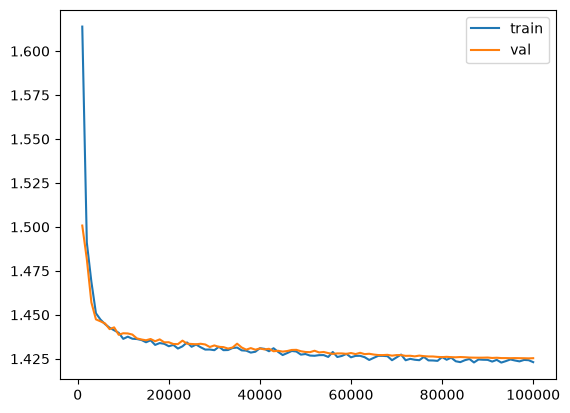

In [ ]:
loss_history = np.load(f"{input_dir}{run}/{run}_loss_history.npz")
plt.plot(loss_history['step'], loss_history["train_loss"], label='train')
plt.plot(loss_history['step'], loss_history["val_loss"], label='val')
plt.legend(loc="upper right")
plt.show()

In [7]:
# ---- notebook: sampling setup ------------------------------------------------
class WrappedModel(ModelWrapper):
    def forward(self, x: torch.Tensor, t: torch.Tensor, **extras):
        xt = torch.cat([x, torch.full((len(x), 1), t.item(), device=x.device)], dim=-1)
        return self.model(xt, **extras)

solver = ODESolver(velocity_model=WrappedModel(vf.eval()))  # create an ODESolver class
n_samples = min(n_samples, len(test))

names = [v.branch for v in var_registry]
i_omega = names.index('MO_Omega')

In [8]:
@torch.no_grad()
def generate(known, x_known=None, n=n_samples, chunk=50000, time_grid=None, return_intermediates=False):
    '''
    known:   (13,) bool, True = variable is fixed to its value in x_known
    x_known: (n, 13) normalized values; only the known columns are used
    returns: (n, 13) normalized samples, or (len(time_grid), n, 13) with return_intermediates
    '''
    known = torch.as_tensor(known, dtype=torch.bool, device=device)
    noise = torch.randn(n, 13, device=device)
    x_init = noise if x_known is None else torch.where(known, x_known.to(device), noise)
    T = torch.tensor([0.0, 1.0], device=device) if time_grid is None else time_grid
    out = [solver.sample(time_grid=T, x_init=x_init[s:s + chunk], method='midpoint', step_size=step_size,
                         return_intermediates=return_intermediates, known=known)
           for s in range(0, n, chunk)]
    return torch.cat(out, dim=-2)

def to_physical(x_norm, like=test):
    '''Reverse the transform with the dataset class: copy `like` (keeps mean/std), swap in x_norm, call inverse().'''
    out = like.subset(np.arange(len(x_norm)))
    out.parameters = x_norm.to(out.parameters.device).clone()
    out.inverse()
    return out.parameters.cpu().numpy()

In [9]:
# Test points used as conditions (random subset, the split indices are sorted by file)
sel = torch.randperm(len(test), generator=torch.Generator().manual_seed(0))[:n_samples].to(test.parameters.device)
test_x = test.parameters[sel]          # normalized
truth_all = to_physical(test.parameters)  # whole test set in physical units
truth = truth_all[sel.cpu().numpy()]      # the selected points in physical units

def _plot_values(x, j):
    '''Column j for plotting; MO_Omega is shown as log10 since it spans orders of magnitude.'''
    return (np.log10(x[:, j]), 'log10(MO_Omega)') if j == i_omega else (x[:, j], names[j])

def plot_marginals(samples, fig_name=None, cols=None, ncols=4, bins=50):  # CHANGED: name of the saved figure
    '''samples: {label: (n, 13) physical array}. Grid of 1D histograms as in dataset_inspection.ipynb;
    the binning range comes from the first entry (0.5-99.5 percentile).'''
    cols = list(range(len(names))) if cols is None else list(cols)
    nrows = (len(cols) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.8 * nrows), squeeze=False, constrained_layout=True)
    for ax, j in zip(axes.flat, cols):
        ref, title = _plot_values(next(iter(samples.values())), j)
        rng = np.nanpercentile(ref[np.isfinite(ref)], [0.5, 99.5])
        for label, x in samples.items():
            v, _ = _plot_values(x, j)
            ax.hist(v[np.isfinite(v)], bins=bins, range=rng, density=True, histtype='step', label=label)
        ax.set_title(title, fontsize=9)
        ax.set_ylabel('Density')
    for ax in axes.flat[len(cols):]:
        ax.set_visible(False)
    axes.flat[0].legend(fontsize=8)
    plt.show()
    if not fig_name is None: save_fig(fig, fig_name)

def plot_corner(samples, fig_name=None, cols=None):  # CHANGED: name of the saved figure
    '''Overlaid corner plots, one color per entry of samples.'''
    cols = list(range(len(names))) if cols is None else list(cols)
    prep = {k: np.column_stack([_plot_values(x, j)[0] for j in cols]) for k, x in samples.items()}
    labels = [_plot_values(next(iter(samples.values())), j)[1] for j in cols]
    ref = next(iter(prep.values()))
    rng = [tuple(np.nanpercentile(ref[:, i], [0.5, 99.5])) for i in range(len(cols))]
    fig = None
    for c, (label, x) in enumerate(prep.items()):
        x = x[np.isfinite(x).all(axis=1)]
        fig = corner.corner(x, fig=fig, color=f'C{c}', labels=labels, range=rng, bins=30,
                            hist_kwargs={'density': True}, plot_datapoints=False, plot_density=False,
                            levels=(0.68, 0.95), label_kwargs={'fontsize': 8})
    handles = [plt.Line2D([], [], color=f'C{c}', label=label) for c, label in enumerate(prep)]
    fig.legend(handles=handles, loc='upper right', fontsize=14)
    plt.show()
    if not fig_name is None: save_fig(fig, fig_name)


def plot_gen_vs_truth(samples, var_names, fig_name=None, cols=None, ncols=4, bins=50):
    """samples: {truth_label:truth (N, D), gen_label:generated data (N, D)}"""
    cols = list(range(len(names))) if cols is None else list(cols)
    nrows = (len(cols) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.8 * nrows), squeeze=False, constrained_layout=True)
    for ax, j in zip(axes.flat, cols):
        values = list(samples.values())
        true_var = values[0][:, j]
        gen_var = values[1][:, j]
        ax.scatter(true_var, gen_var, s=1, alpha=0.5)
        lims = [min(true_var.min(), gen_var.min()), max(true_var.max(), gen_var.max())]
        ax.plot(lims, lims, 'r--', lw=1)
        ax.set_title(var_names[j], fontsize=9)
        labels = list(samples.keys())
        ax.set_xlabel(labels[0]); ax.set_ylabel(labels[1])
    for ax in axes.flat[len(cols):]:
        ax.set_visible(False)
    axes.flat[0].legend(fontsize=8)
    plt.show()
    if not fig_name is None: save_fig(fig, fig_name)

In [12]:
# ---- sampling: here ("run"), or hand off to sample_fm.py ("save" -> sbatch -> "load") ----
x_fixed = torch.zeros(n_samples, 13, device=device)
x_fixed[:, i_omega] = (np.log10(omega_0) - test.mean[i_omega].item()) / test.std[i_omega].item()  # same transform as the data

jobs = {   # name -> keyword arguments of generate()
    'joint':                    dict(known=masks[2]),                    # mask 2: unconditional
    'omega_given_inputs':       dict(known=masks[0], x_known=test_x),    # mask 0: inputs known
    'inputs_given_omega':       dict(known=masks[1], x_known=test_x),    # mask 1: Omega known
    'inputs_given_omega_fixed': dict(known=masks[1], x_known=x_fixed),   # mask 1: Omega = omega_0
}
settings = dict(run=run, final=final, step_size=step_size, n_samples=n_samples, omega_0=omega_0)
inputs_path = f"{input_dir}{run}/sampling_inputs.pt"
outputs_path = f"{input_dir}{run}/sampling_outputs.pt"

if sample_mode == "run":
    results = {name: generate(**job) for name, job in jobs.items()}

elif sample_mode == "save":
    jobs_cpu = {name: {k: v.cpu() for k, v in job.items()} | {'n': n_samples} for name, job in jobs.items()}
    torch.save({'settings': settings, 'jobs': jobs_cpu}, inputs_path)
    print(f"saved {inputs_path}")
    raise SystemExit(f"Now sample on a GPU:  sbatch tests/slurm/sample_fm.sbatch {run}\n"
                     f"then set sample_mode = 'load' and run the notebook again.")

elif sample_mode == "load":
    outputs = torch.load(outputs_path, map_location=device)
    if outputs['settings'] != settings:
        raise ValueError(f"{outputs_path} was sampled with {outputs['settings']}, "
                         f"but the notebook uses {settings}. Run 'save' and sample_fm.py again.")
    missing = set(jobs) - set(outputs['results'])
    if missing:
        raise ValueError(f"{outputs_path} has no results for {sorted(missing)}. Resubmit sample_fm.sbatch.")
    results = {name: x.to(device) for name, x in outputs['results'].items()}

else:
    raise ValueError(f"sample_mode must be 'run', 'save' or 'load', not {sample_mode!r}")

In [ ]:
# ---- 1. Joint distribution p(inputs, Omega) ---------------------------------
gen_joint = to_physical(results['joint'])
plot_marginals({'test data': truth, 'generated': gen_joint})

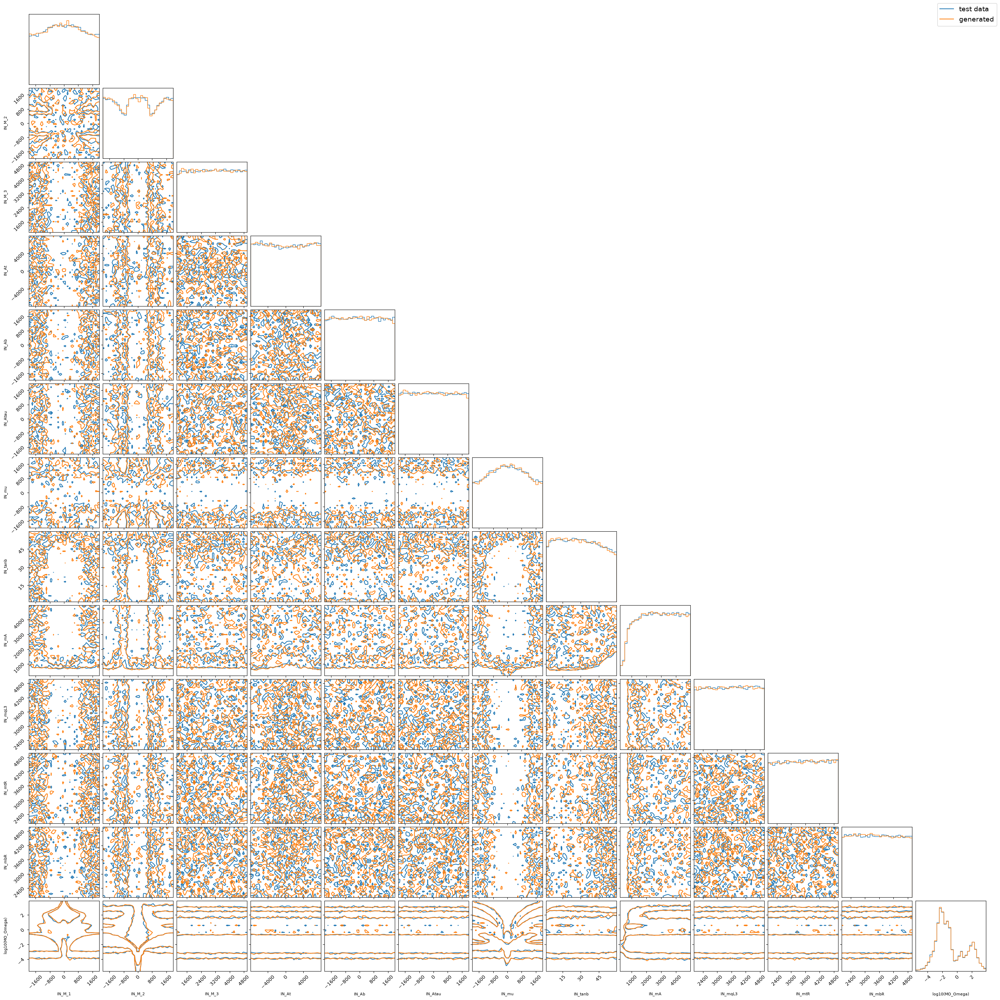

In [ ]:
plot_corner({'test data': truth, 'generated': gen_joint})

Probability distribution path for the joint distribution of M1 and Omega (Who needs this?)

In [ ]:
# ---- 2. Relic density from the inputs p(Omega | inputs) ---------------------
gen_omega = to_physical(results['omega_given_inputs'])
t_om, g_om = truth[:, i_omega], gen_omega[:, i_omega]
m1 = np.abs(truth[:, names.index('IN_M_1')])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)

ax = axes[0]
ax.scatter(t_om, g_om, s=1, alpha=0.5)
lims = [min(t_om.min(), g_om.min()), max(t_om.max(), g_om.max())]
ax.plot(lims, lims, 'r--', lw=1)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('true MO_Omega'); ax.set_ylabel('generated MO_Omega')

ax = axes[1]
ax.hist(np.log10(g_om / t_om), bins=60)
ax.set_xlabel('log10(generated / true)'); ax.set_ylabel('Count')

ax = axes[2]  # as in dataset_inspection.ipynb, with |M_1| in place of m_chi_10
ax.scatter(m1, t_om, s=1, label='test data')
ax.scatter(m1, g_om, s=1, alpha=0.5, label='generated')
# ax.axvline(91.19/2, color='red', linestyle='--', label=r'$m_Z/2$')
# ax.axvline(125.25/2, color='blue', linestyle='--', label=r'$m_h/2$')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlim(1e1, 1e4); ax.set_ylim(1e-4, 1e1)
ax.set_xlabel('|IN_M_1|'); ax.set_ylabel('MO_Omega')
ax.legend(markerscale=5, fontsize=8)
plt.show()

print(f"median |log10(generated/true)| = {np.median(np.abs(np.log10(g_om / t_om))):.3f}")

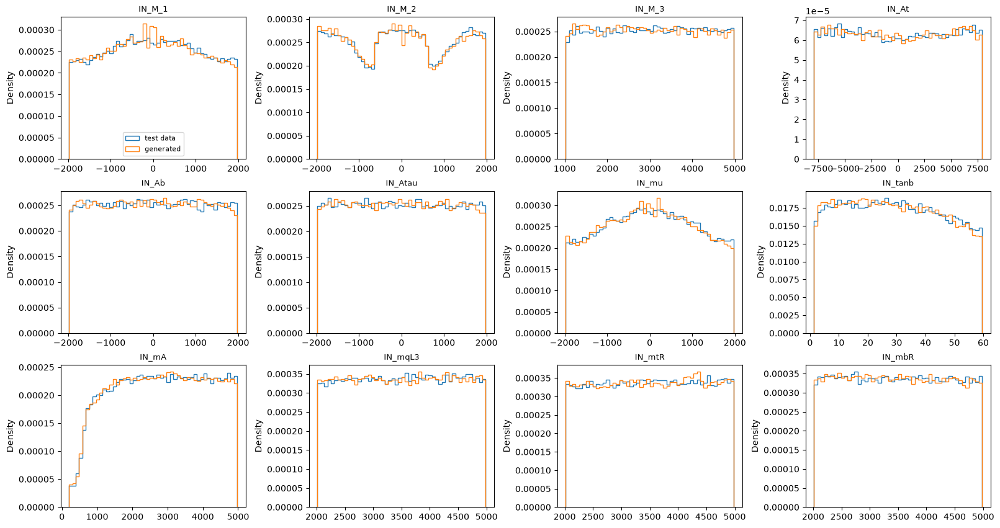

In [13]:
# ---- 3. Inputs from the relic density p(inputs | Omega) ---------------------
gen_inputs = to_physical(results['inputs_given_omega'])
plot_marginals({'test data': truth, 'generated': gen_inputs}, cols=range(12))

/tmp/ipykernel_8768/1480088054.py:67: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes.flat[0].legend(fontsize=8)


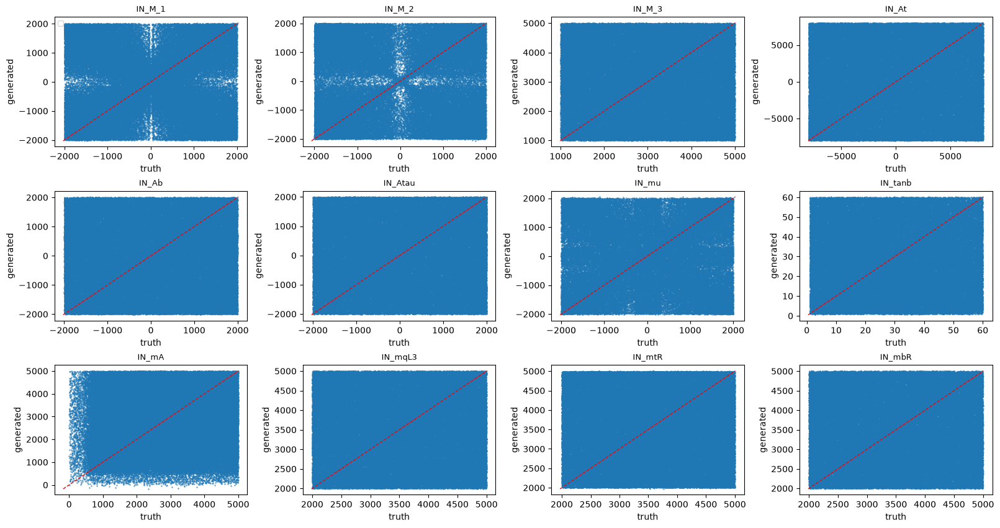

In [9]:
plot_gen_vs_truth({'truth': truth, 'generated': gen_inputs}, var_names=input_params, cols=range(12))

test points with |log10(Omega) - log10(0.12)| < 0.05: 6087


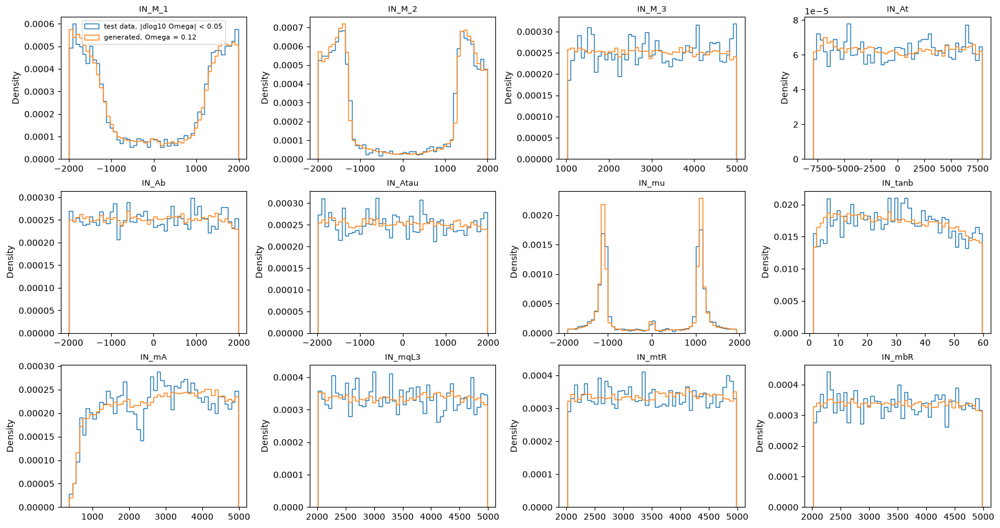

In [14]:
gen_fixed = to_physical(results['inputs_given_omega_fixed'])

band = truth_all[np.abs(np.log10(truth_all[:, i_omega]) - np.log10(omega_0)) < 0.05]
print(f"test points with |log10(Omega) - log10({omega_0})| < 0.05: {len(band)}")
plot_marginals({f'test data, |dlog10 Omega| < 0.05': band, f'generated, Omega = {omega_0}': gen_fixed},
                cols=range(12))


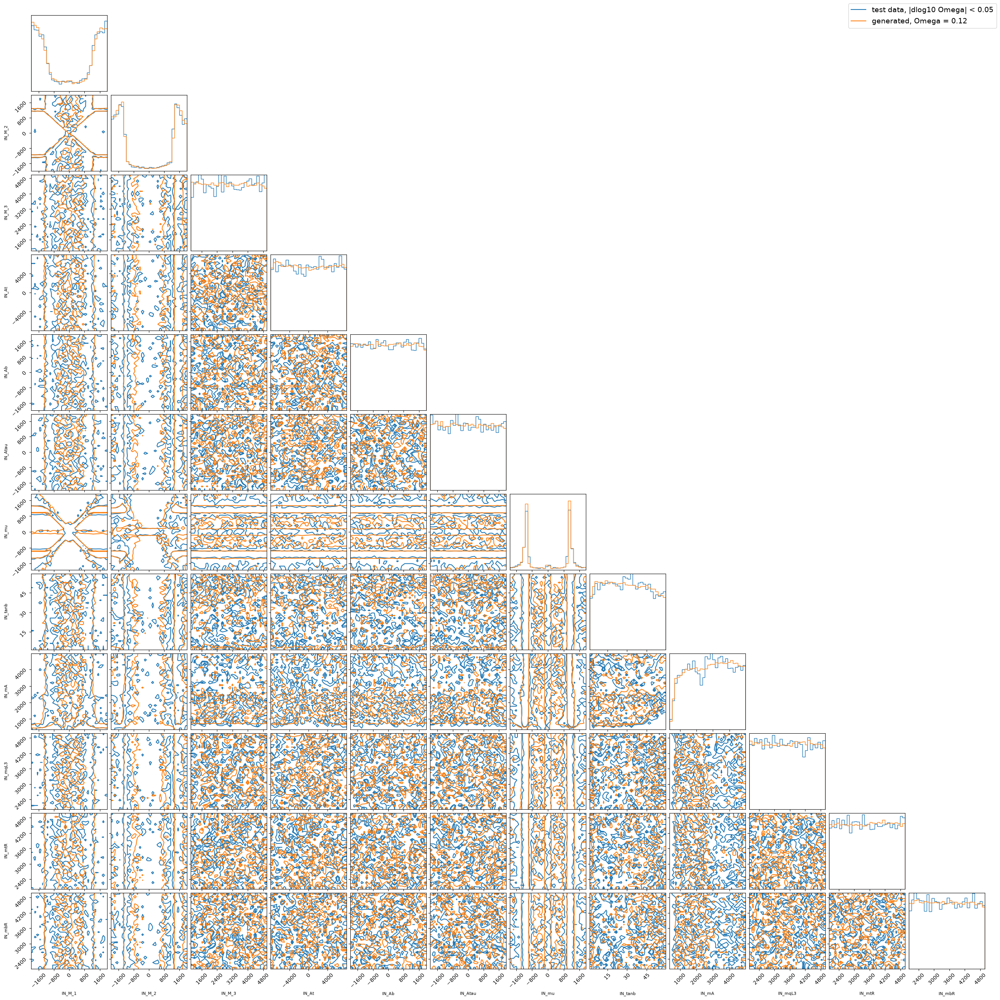

In [16]:
plot_corner({f'test data, |dlog10 Omega| < 0.05': band, f'generated, Omega = {omega_0}': gen_fixed},
                cols=range(12))

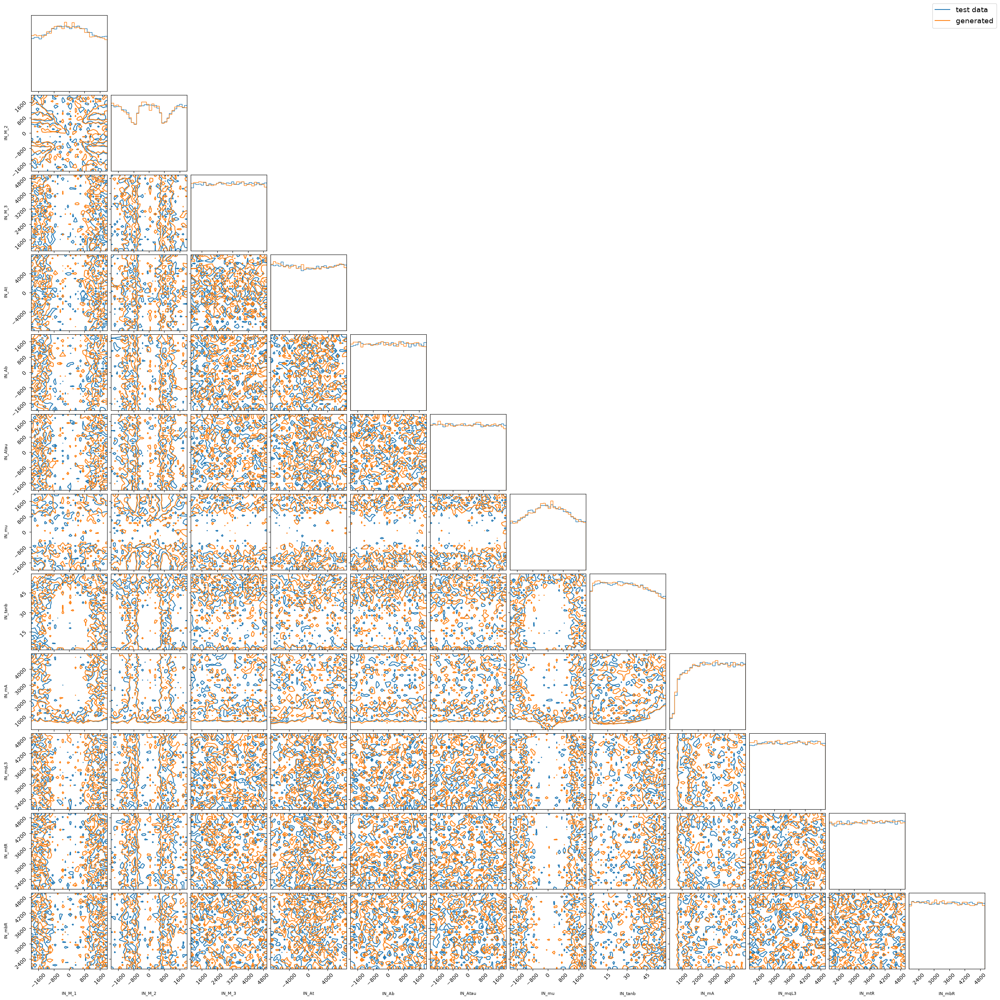

In [ ]:
plot_corner({'test data': truth, 'generated': gen_inputs}, cols=range(12))